# Divergence-based bandwidth chains for a Gaussian KDE

This notebook implements the experiment in eight blocks:

1. draw $X_1,\ldots,X_n \sim N(0,\sigma^2)$;
2. construct Rényi, $\alpha$-, KL, reverse-KL, and Jensen–Shannon divergence matrices on a geometric bandwidth grid;
3. transform divergence to similarity with $S_{ij}=\exp(-D_{ij})$;
4. form the Perron–Doob chain, compute its stationary distribution, and mark its maximum;
5. compute and plot the exact finite-sample MISE curve;
6. compare the MISE-oracle KDE and all divergence-selected KDEs side by side, including their realized ISE values;
7. test fixed-sample-size stability under repeated resampling;
8. run a switchable fixed/scaled-grid consistency experiment over $n=100,200,\ldots,1000$.

All experiment controls are collected in the next cell. The same `ALPHA` parameter is used for Rényi and $\alpha$-divergence. The default $0<\alpha<1$ makes every pairwise power integral finite; KL, reverse KL, and Jensen–Shannon are computed alongside them.

In [1]:
from __future__ import annotations

import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import fftconvolve
from scipy.special import logsumexp
from scipy.stats import norm

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=5, suppress=True)

## Experiment parameters

Change this cell and rerun all cells below it. Set `GRID_MODE = "fixed"` for the absolute grid $[0.01,2]$, or `GRID_MODE = "scaled"` for $h_i(n)=c_i n^{-1/5}$ with $c_i\in[0.01,2]$. `N_BANDWIDTHS` controls the fineness.

In [2]:
# Sampling controls
N_SAMPLES = 200
SIGMA2 = 1.0
RANDOM_SEED = 12345

# Rényi parameter: use ALPHA > 0. ALPHA = 1 computes the KL limit.
ALPHA = 0.5

# Bandwidth-grid switch: choose "fixed" or "scaled".
GRID_MODE = "scaled"

# In fixed mode these are h_min and h_max. In scaled mode they are c_min and c_max.
H_MIN = 0.01
H_MAX = 2.0
N_BANDWIDTHS = 50

def bandwidth_grid_for_sample_size(sample_size: int) -> np.ndarray:
    """Build either h_i or h_i(n)=c_i*n^(-1/5), depending on GRID_MODE."""
    if GRID_MODE not in {"fixed", "scaled"}:
        raise ValueError('GRID_MODE must be either "fixed" or "scaled".')
    if sample_size < 1:
        raise ValueError("sample_size must be positive.")
    base_grid = np.geomspace(H_MIN, H_MAX, N_BANDWIDTHS)
    if GRID_MODE == "fixed":
        return base_grid
    return base_grid * sample_size ** (-1.0 / 5.0)

# Deterministic truncated composite trapezoidal quadrature.
TRUNCATION_EPSILON = 1e-8
N_QUADRATURE_NODES = 4001

## 1. Sampling block

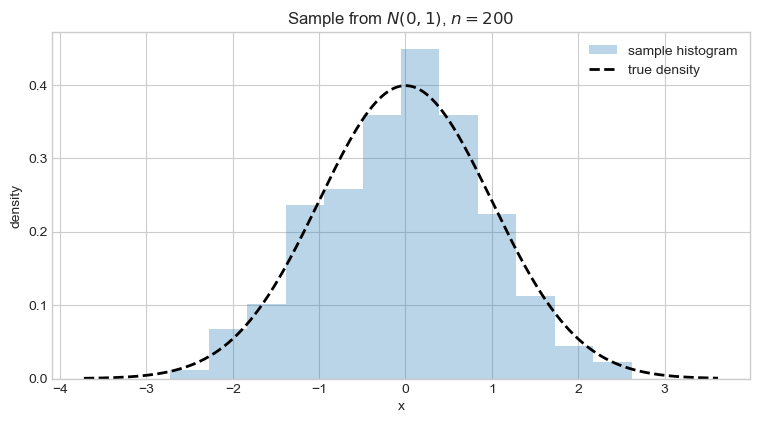

sample mean     = 0.00332536
sample variance = 0.917653


In [3]:
if N_SAMPLES < 1:
    raise ValueError("N_SAMPLES must be positive.")
if SIGMA2 <= 0:
    raise ValueError("SIGMA2 must be strictly positive.")

rng = np.random.default_rng(RANDOM_SEED)
X = rng.normal(loc=0.0, scale=np.sqrt(SIGMA2), size=N_SAMPLES)

plot_x = np.linspace(X.min() - np.sqrt(SIGMA2), X.max() + np.sqrt(SIGMA2), 800)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(X, bins="auto", density=True, alpha=0.30, color="tab:blue", label="sample histogram")
ax.plot(plot_x, norm.pdf(plot_x, loc=0.0, scale=np.sqrt(SIGMA2)), "k--", lw=2, label="true density")
ax.set(title=rf"Sample from $N(0,{SIGMA2:g})$, $n={N_SAMPLES}$", xlabel="x", ylabel="density")
ax.legend()
plt.show()

print(f"sample mean     = {X.mean():.6g}")
print(f"sample variance = {X.var(ddof=1):.6g}")

## 2. Divergence matrix assembly

For the Gaussian KDE $\widehat f_h$, define $I_\alpha(p,q)=\int p^\alpha q^{1-\alpha}$. The two power divergences are

$$R_\alpha(p\|q)=\frac{\log I_\alpha(p,q)}{\alpha-1},\qquad A_\alpha(p\|q)=\frac{I_\alpha(p,q)-1}{\alpha(\alpha-1)}.$$

The same quadrature also produces $KL(p\|q)$, reverse $KL(p\|q)=KL(q\|p)$, and Jensen–Shannon divergence. KDE log-densities are evaluated stably with `logsumexp`; the finite integration interval leaves at most `TRUNCATION_EPSILON` KDE probability mass outside it. For $\alpha=1$, both power families are evaluated through their KL limit.

> For $\alpha>1$, a small omitted KDE tail does not by itself bound the omitted Rényi integrand, and some ordered Gaussian-bandwidth pairs have infinite divergence. The code identifies those pairs from their Gaussian tail rates and records `np.inf`.

In [4]:
def composite_trapezoid_log_weights(x_grid: np.ndarray) -> np.ndarray:
    """Log-weights for the composite trapezoidal rule on an equally spaced grid."""
    x_grid = np.asarray(x_grid, dtype=float)
    if x_grid.ndim != 1 or len(x_grid) < 2:
        raise ValueError("x_grid must contain at least two nodes.")
    steps = np.diff(x_grid)
    if not np.allclose(steps, steps[0]):
        raise ValueError("This implementation expects an equally spaced grid.")
    weights = np.full(len(x_grid), steps[0])
    weights[[0, -1]] *= 0.5
    return np.log(weights)


def gaussian_kde_log_values(x_grid: np.ndarray, samples: np.ndarray, h_grid: np.ndarray) -> np.ndarray:
    """Evaluate all one-dimensional Gaussian KDEs in the log domain."""
    x_grid = np.asarray(x_grid, dtype=float)
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    result = np.empty((len(h_grid), len(x_grid)))
    for i, h in enumerate(h_grid):
        standardized = (x_grid[:, None] - samples[None, :]) / h
        log_components = -0.5 * standardized**2 - np.log(h * np.sqrt(2 * np.pi))
        result[i] = logsumexp(log_components, axis=1) - np.log(len(samples))
    return result


DIVERGENCE_SPECS = [
    ("renyi", rf"Rényi $R_{{{ALPHA:g}}}$", "tab:red"),
    ("alpha", rf"$\alpha$-divergence $A_{{{ALPHA:g}}}$", "tab:orange"),
    ("kl", "KL", "tab:blue"),
    ("reverse_kl", "reverse KL", "tab:purple"),
    ("js", "Jensen–Shannon", "tab:brown"),
]
DIVERGENCE_LABELS = {key: label for key, label, _ in DIVERGENCE_SPECS}
DIVERGENCE_COLORS = {key: color for key, _, color in DIVERGENCE_SPECS}


def assemble_all_divergence_matrices(
    normalized_log_densities: np.ndarray,
    log_weights: np.ndarray,
    alpha: float,
    bandwidths: np.ndarray,
) -> dict[str, np.ndarray]:
    """Rényi, alpha, KL, reverse-KL, and JS divergence matrices."""
    if alpha <= 0:
        raise ValueError("ALPHA must be strictly positive.")

    log_f = np.asarray(normalized_log_densities, dtype=float)
    density = np.exp(log_f)
    weights = np.exp(log_weights)
    number_of_bandwidths = len(log_f)

    # KL(f_i || f_j) and its reversed orientation.
    weighted_density = density * weights[None, :]
    self_terms = np.sum(weighted_density * log_f, axis=1)
    kl = self_terms[:, None] - weighted_density @ log_f.T
    reverse_kl = kl.T.copy()

    # The alpha and Rényi divergences share I_alpha = integral f_i^alpha f_j^(1-alpha).
    if np.isclose(alpha, 1.0):
        renyi = kl.copy()
        alpha_divergence = kl.copy()
    else:
        log_integrals = np.empty((number_of_bandwidths, number_of_bandwidths))
        for i in range(number_of_bandwidths):
            log_integrands = (
                alpha * log_f[i][None, :]
                + (1.0 - alpha) * log_f
                + log_weights[None, :]
            )
            log_integrals[i] = logsumexp(log_integrands, axis=1)
        renyi = log_integrals / (alpha - 1.0)
        alpha_divergence = np.expm1(log_integrals) / (alpha * (alpha - 1.0))

        # Some ordered Gaussian-bandwidth pairs have infinite full-line divergence for alpha > 1.
        if alpha > 1.0:
            h_i = bandwidths[:, None]
            h_j = bandwidths[None, :]
            divergent_tails = alpha / h_i**2 + (1.0 - alpha) / h_j**2 <= 0.0
            renyi[divergent_tails] = np.inf
            alpha_divergence[divergent_tails] = np.inf

    # Symmetric Jensen–Shannon divergence. Work one source row at a time to limit memory.
    js = np.empty((number_of_bandwidths, number_of_bandwidths))
    for i in range(number_of_bandwidths):
        mixtures = 0.5 * (density[i][None, :] + density)
        log_mixtures = np.log(np.maximum(mixtures, 1e-300))
        first = np.sum(weights * density[i] * (log_f[i] - log_mixtures), axis=1)
        second = np.sum(weights[None, :] * density * (log_f - log_mixtures), axis=1)
        js[i] = 0.5 * (first + second)

    matrices = {
        "renyi": renyi,
        "alpha": alpha_divergence,
        "kl": kl,
        "reverse_kl": reverse_kl,
        "js": js,
    }
    for matrix in matrices.values():
        finite = np.isfinite(matrix)
        matrix[finite] = np.maximum(matrix[finite], 0.0)
        np.fill_diagonal(matrix, 0.0)
    return matrices

In [5]:
if not (0 < H_MIN < H_MAX):
    raise ValueError("Require 0 < H_MIN < H_MAX.")
if N_BANDWIDTHS < 2:
    raise ValueError("N_BANDWIDTHS must be at least 2.")
if not (0 < TRUNCATION_EPSILON < 1):
    raise ValueError("TRUNCATION_EPSILON must lie in (0, 1).")
if N_QUADRATURE_NODES < 2:
    raise ValueError("N_QUADRATURE_NODES must be at least 2.")

bandwidths = bandwidth_grid_for_sample_size(N_SAMPLES)
tail_z = norm.ppf(1.0 - TRUNCATION_EPSILON / 2.0)
integration_left = X.min() - tail_z * bandwidths.max()
integration_right = X.max() + tail_z * bandwidths.max()
x_quadrature = np.linspace(integration_left, integration_right, N_QUADRATURE_NODES)
log_weights = composite_trapezoid_log_weights(x_quadrature)

raw_log_densities = gaussian_kde_log_values(x_quadrature, X, bandwidths)
log_masses = logsumexp(raw_log_densities + log_weights[None, :], axis=1)
normalized_log_densities = raw_log_densities - log_masses[:, None]

divergence_matrices = assemble_all_divergence_matrices(
    normalized_log_densities, log_weights, ALPHA, bandwidths
)
divergence_matrix = divergence_matrices["renyi"]  # backward-compatible alias

print(f"grid mode: {GRID_MODE}")
print(f"bandwidth grid for n={N_SAMPLES}: {N_BANDWIDTHS} points from {bandwidths[0]:.4g} to {bandwidths[-1]:.4g}")
print(f"integration interval: [{integration_left:.4g}, {integration_right:.4g}]")
print(f"quadrature nodes: {N_QUADRATURE_NODES}")
print(f"largest estimated KDE mass loss: {np.max(np.maximum(1.0 - np.exp(log_masses), 0.0)):.3e}")
for key, label, _ in DIVERGENCE_SPECS:
    matrix = divergence_matrices[key]
    print(f"{label:32s}: finite entries {np.isfinite(matrix).sum()}/{matrix.size}")

grid mode: scaled
bandwidth grid for n=200: 50 points from 0.003466 to 0.6931
integration interval: [-6.695, 6.59]
quadrature nodes: 4001
largest estimated KDE mass loss: 5.315e-11
Rényi $R_{0.5}$                 : finite entries 2500/2500
$\alpha$-divergence $A_{0.5}$   : finite entries 2500/2500
KL                              : finite entries 2500/2500
reverse KL                      : finite entries 2500/2500
Jensen–Shannon                  : finite entries 2500/2500


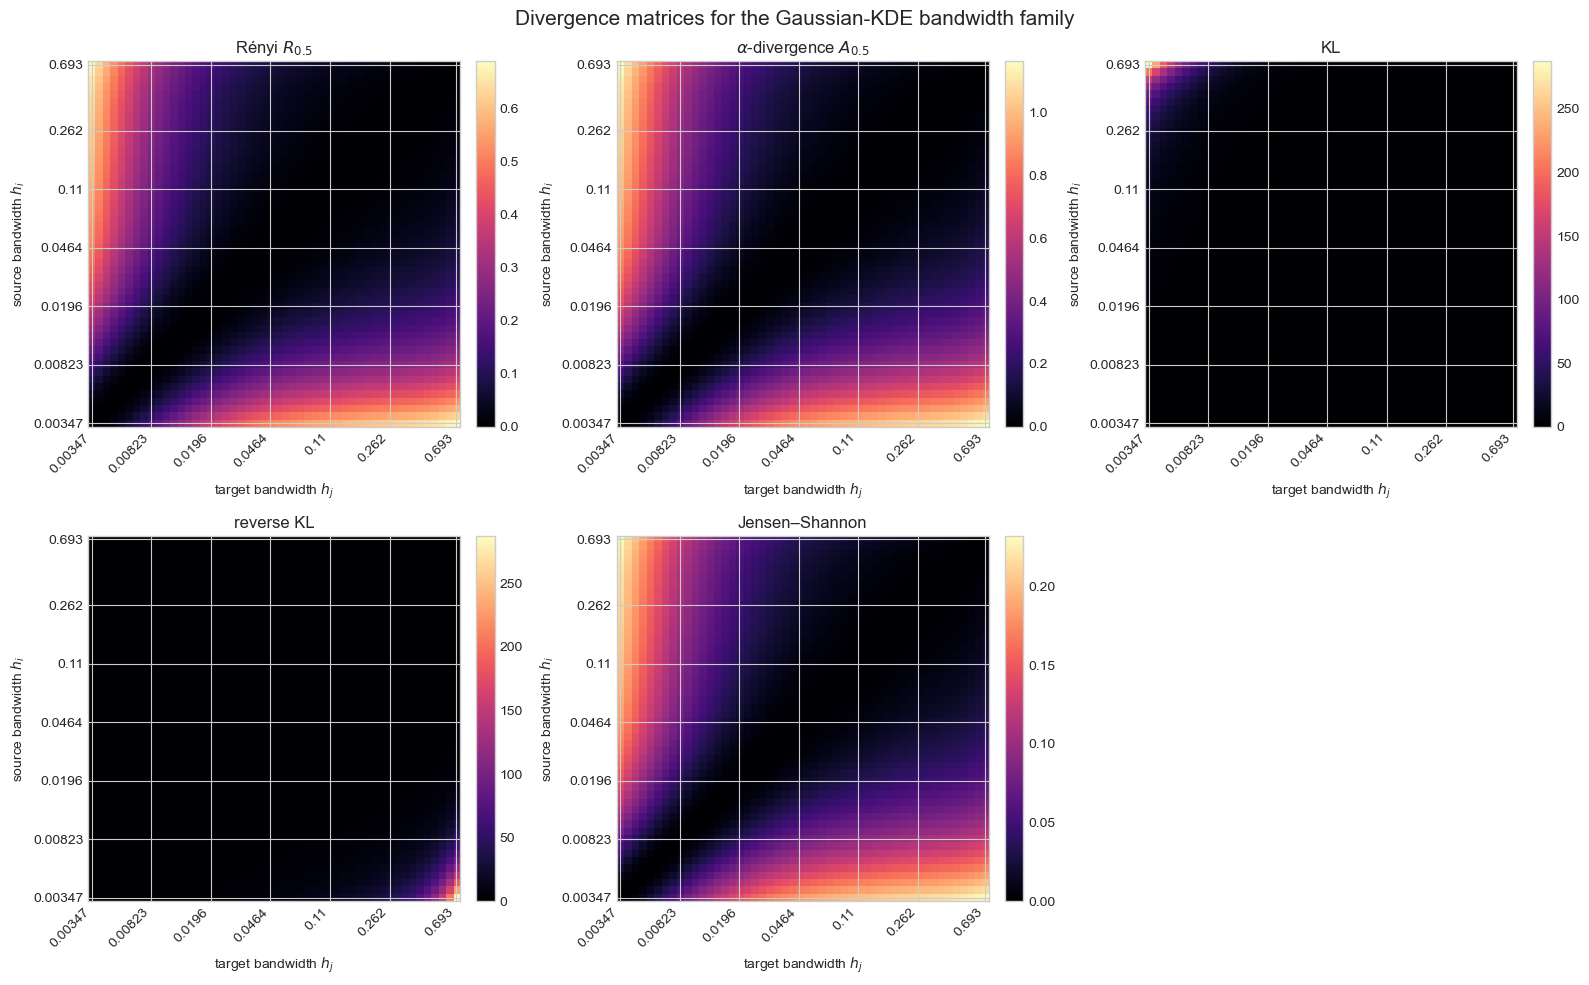

In [6]:
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("lightgray")
tick_indices = np.unique(np.linspace(0, N_BANDWIDTHS - 1, min(7, N_BANDWIDTHS), dtype=int))
tick_labels = [f"{bandwidths[k]:.3g}" for k in tick_indices]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (key, label, _) in zip(axes.flat, DIVERGENCE_SPECS):
    masked_divergence = np.ma.masked_invalid(divergence_matrices[key])
    image = ax.imshow(masked_divergence, origin="lower", aspect="auto", cmap=cmap)
    ax.set_xticks(tick_indices, tick_labels, rotation=45, ha="right")
    ax.set_yticks(tick_indices, tick_labels)
    ax.set_xlabel(r"target bandwidth $h_j$")
    ax.set_ylabel(r"source bandwidth $h_i$")
    ax.set_title(label)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
axes.flat[-1].axis("off")
fig.suptitle("Divergence matrices for the Gaussian-KDE bandwidth family", fontsize=15)
plt.tight_layout()
plt.show()

## 3. Similarity transformation

For now the transformation is exactly $S_{ij}=\exp(-D_{ij})$. Infinite divergences therefore become zero similarities.

In [7]:
similarity_matrices = {}
for key, label, _ in DIVERGENCE_SPECS:
    similarity = np.exp(-divergence_matrices[key])
    np.fill_diagonal(similarity, 1.0)
    similarity_matrices[key] = similarity
    print(f"{label:32s}: similarity range [{similarity.min():.6g}, {similarity.max():.6g}]")
similarity_matrix = similarity_matrices["renyi"]  # backward-compatible alias

Rényi $R_{0.5}$                 : similarity range [0.502582, 1]
$\alpha$-divergence $A_{0.5}$   : similarity range [0.312147, 1]
KL                              : similarity range [1.46899e-125, 1]
reverse KL                      : similarity range [1.46899e-125, 1]
Jensen–Shannon                  : similarity range [0.79274, 1]


## 4. Perron–Doob chain and stationary distribution

If $Sr=\rho r$ and $\ell^T S=\rho\ell^T$, the Doob transition matrix and its stationary distribution are

$$P_{ij}=\frac{S_{ij}r_j}{\rho r_i},\qquad \pi_i=\frac{\ell_i r_i}{\sum_k \ell_k r_k}. $$

In [8]:
def perron_eigenpair(matrix: np.ndarray) -> tuple[float, np.ndarray]:
    """Dominant eigenvalue and nonnegative eigenvector, normalized to sum one."""
    eigenvalues, eigenvectors = np.linalg.eig(np.asarray(matrix, dtype=float))
    index = int(np.argmax(eigenvalues.real))
    eigenvalue = float(eigenvalues[index].real)
    vector = np.real(eigenvectors[:, index])
    if vector.sum() < 0:
        vector = -vector
    vector = np.maximum(vector, 0.0)
    if vector.sum() == 0:
        vector = np.abs(np.real(eigenvectors[:, index]))
    vector /= vector.sum()
    return eigenvalue, vector


def doob_transform(similarity: np.ndarray) -> dict[str, np.ndarray | float]:
    """Compute the Perron–Doob transition matrix and its stationary law."""
    similarity = np.asarray(similarity, dtype=float)
    rho_right, right = perron_eigenpair(similarity)
    rho_left, left = perron_eigenpair(similarity.T)
    if np.any(right <= 0) or np.any(left <= 0):
        raise RuntimeError("The similarity matrix is not irreducible enough to produce strictly positive Perron vectors.")

    rho = float(left @ (similarity @ right) / (left @ right))
    transition = similarity * right[None, :] / (rho * right[:, None])
    transition /= transition.sum(axis=1, keepdims=True)
    stationary = left * right
    stationary /= stationary.sum()

    return {
        "perron_eigenvalue": rho,
        "left_perron_vector": left,
        "right_perron_vector": right,
        "transition_matrix": transition,
        "stationary_distribution": stationary,
        "left_right_eigenvalue_difference": abs(rho_left - rho_right),
    }

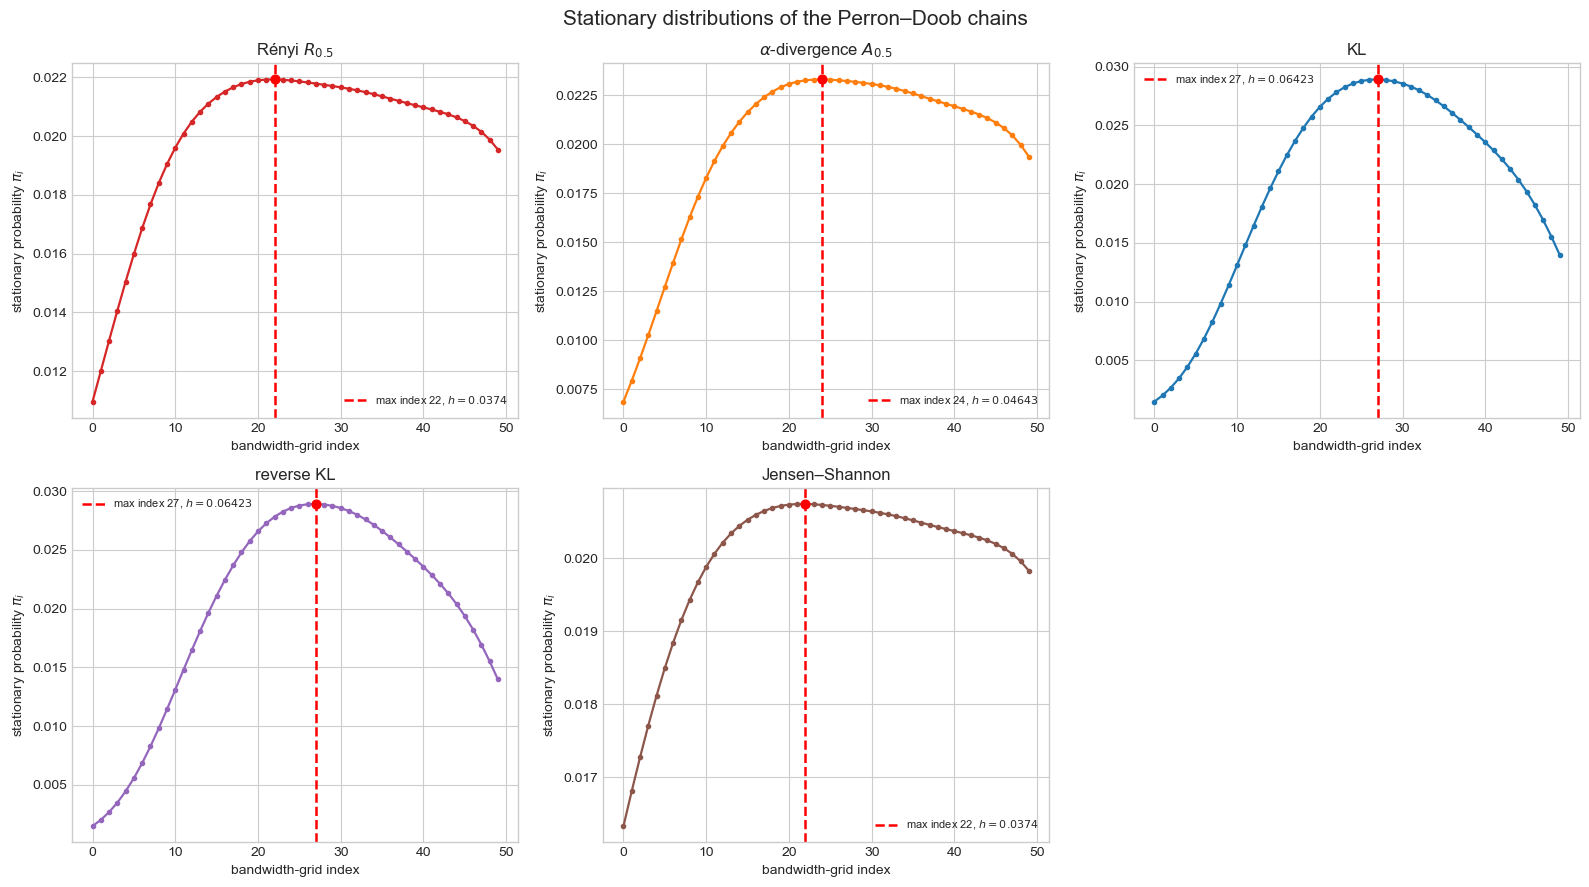

Rényi $R_{0.5}$                 : index=22, h=0.037403265, row error=2.22e-16, stationarity error=4.34e-17
$\alpha$-divergence $A_{0.5}$   : index=24, h=0.046433252, row error=2.22e-16, stationarity error=2.78e-17
KL                              : index=27, h=0.064225647, row error=2.22e-16, stationarity error=4.68e-17
reverse KL                      : index=27, h=0.064225647, row error=2.22e-16, stationarity error=2.43e-17
Jensen–Shannon                  : index=22, h=0.037403265, row error=3.33e-16, stationarity error=2.78e-17


In [9]:
doob_results = {key: doob_transform(similarity_matrices[key]) for key, _, _ in DIVERGENCE_SPECS}
stationary_distributions = {key: result["stationary_distribution"] for key, result in doob_results.items()}
spectral_selected_indices = {key: int(np.argmax(stationary_distributions[key])) for key, _, _ in DIVERGENCE_SPECS}
spectral_selected_bandwidths = {key: float(bandwidths[index]) for key, index in spectral_selected_indices.items()}

indices = np.arange(N_BANDWIDTHS)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (key, label, color) in zip(axes.flat, DIVERGENCE_SPECS):
    stationary = stationary_distributions[key]
    maximum = spectral_selected_indices[key]
    selected_h = spectral_selected_bandwidths[key]
    ax.plot(indices, stationary, marker="o", ms=3, lw=1.6, color=color)
    ax.axvline(maximum, color="red", ls="--", lw=1.8, label=rf"max index {maximum}, $h={selected_h:.4g}$")
    ax.scatter([maximum], [stationary[maximum]], color="red", s=40, zorder=3)
    ax.set(title=label, xlabel="bandwidth-grid index", ylabel=r"stationary probability $\pi_i$")
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Stationary distributions of the Perron–Doob chains", fontsize=15)
plt.tight_layout()
plt.show()

for key, label, _ in DIVERGENCE_SPECS:
    result = doob_results[key]
    transition = result["transition_matrix"]
    stationary = result["stationary_distribution"]
    row_error = np.max(np.abs(transition.sum(axis=1) - 1.0))
    stationary_error = np.max(np.abs(stationary @ transition - stationary))
    print(
        f"{label:32s}: index={spectral_selected_indices[key]:2d}, "
        f"h={spectral_selected_bandwidths[key]:.8g}, "
        f"row error={row_error:.2e}, stationarity error={stationary_error:.2e}"
    )

# Rényi aliases retained for direct comparison with the earlier blocks.
doob_result = doob_results["renyi"]
transition_matrix = doob_result["transition_matrix"]
stationary_distribution = doob_result["stationary_distribution"]
max_index = spectral_selected_indices["renyi"]
selected_bandwidth = spectral_selected_bandwidths["renyi"]

## 5. Exact MISE curve

For $X_i\sim N(0,\sigma^2)$ and the Gaussian kernel, the exact finite-sample mean integrated squared error is

$$\operatorname{MISE}(h)=\frac{1}{2\sqrt{\pi}nh}+\frac{1-1/n}{2\sqrt{\pi}\sqrt{\sigma^2+h^2}}-\frac{2}{\sqrt{2\pi(2\sigma^2+h^2)}}+\frac{1}{2\sqrt{\pi}\sigma}. $$

The oracle bandwidth below is the continuous minimizer of this expression constrained to the experiment interval $[h_{\min},h_{\max}]$.

In [10]:
def exact_gaussian_kde_mise(
    h: float | np.ndarray,
    sample_size: int,
    sigma2: float,
) -> float | np.ndarray:
    """Exact finite-sample MISE for a Gaussian target and Gaussian KDE."""
    h = np.asarray(h, dtype=float)
    if np.any(h <= 0):
        raise ValueError("Every bandwidth must be strictly positive.")
    sigma = np.sqrt(sigma2)
    return (
        1.0 / (2.0 * np.sqrt(np.pi) * sample_size * h)
        + (1.0 - 1.0 / sample_size)
        / (2.0 * np.sqrt(np.pi) * np.sqrt(sigma2 + h**2))
        - 2.0 / np.sqrt(2.0 * np.pi * (2.0 * sigma2 + h**2))
        + 1.0 / (2.0 * np.sqrt(np.pi) * sigma)
    )


def exact_gaussian_kde_ise(samples: np.ndarray, h: float, sigma2: float) -> float:
    """Exact realized ISE of one Gaussian KDE against N(0, sigma2)."""
    samples = np.asarray(samples, dtype=float)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2
    kde_squared = np.exp(-squared_differences / (4.0 * h**2)).mean()
    kde_squared /= 2.0 * np.sqrt(np.pi) * h
    cross = np.exp(-samples**2 / (2.0 * (sigma2 + h**2))).mean()
    cross /= np.sqrt(2.0 * np.pi * (sigma2 + h**2))
    true_squared = 1.0 / (2.0 * np.sqrt(np.pi) * np.sqrt(sigma2))
    return float(max(kde_squared - 2.0 * cross + true_squared, 0.0))


def gaussian_kde_density(x_grid: np.ndarray, samples: np.ndarray, h: float) -> np.ndarray:
    """Evaluate a one-dimensional Gaussian KDE."""
    standardized = (x_grid[:, None] - samples[None, :]) / h
    return np.exp(-0.5 * standardized**2).mean(axis=1) / (h * np.sqrt(2.0 * np.pi))

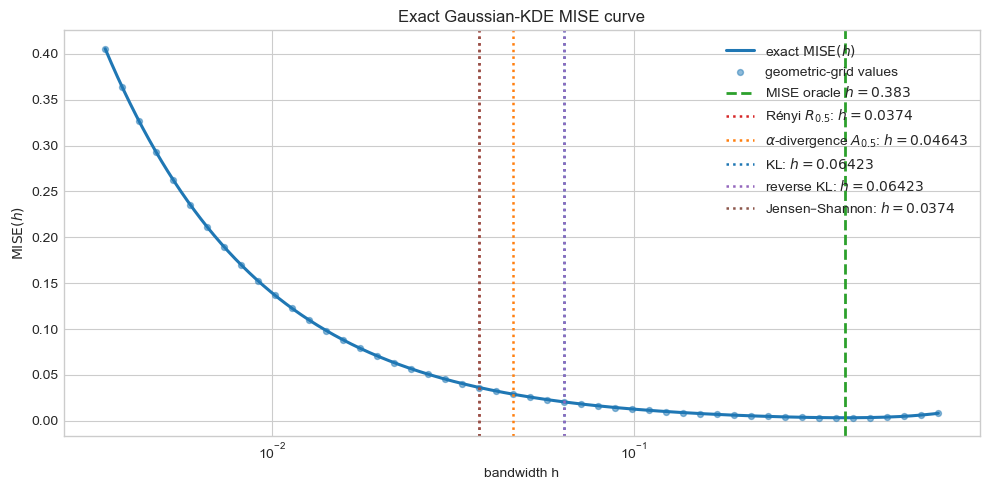

continuous MISE-oracle bandwidth: 0.38303955
continuous oracle MISE: 0.003322337701
Rényi $R_{0.5}$                 : h=0.037403265, MISE=0.03630053082
$\alpha$-divergence $A_{0.5}$   : h=0.046433252, MISE=0.02896766614
KL                              : h=0.064225647, MISE=0.02055454762
reverse KL                      : h=0.064225647, MISE=0.02055454762
Jensen–Shannon                  : h=0.037403265, MISE=0.03630053082
geometric-grid oracle index: 44
geometric-grid oracle bandwidth: 0.40366865


In [11]:
mise_grid_values = exact_gaussian_kde_mise(bandwidths, N_SAMPLES, SIGMA2)
mise_plot_h = np.geomspace(bandwidths[0], bandwidths[-1], 2000)
mise_plot_values = exact_gaussian_kde_mise(mise_plot_h, N_SAMPLES, SIGMA2)

oracle_result = minimize_scalar(
    lambda h: float(exact_gaussian_kde_mise(h, N_SAMPLES, SIGMA2)),
    bounds=(float(bandwidths[0]), float(bandwidths[-1])),
    method="bounded",
)
if not oracle_result.success:
    raise RuntimeError(oracle_result.message)

oracle_bandwidth = float(oracle_result.x)
oracle_mise = float(oracle_result.fun)
spectral_mise_values = {
    key: float(exact_gaussian_kde_mise(h, N_SAMPLES, SIGMA2))
    for key, h in spectral_selected_bandwidths.items()
}
grid_oracle_index = int(np.argmin(mise_grid_values))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mise_plot_h, mise_plot_values, lw=2.2, color="tab:blue", label=r"exact $\operatorname{MISE}(h)$")
ax.scatter(bandwidths, mise_grid_values, s=18, color="tab:blue", alpha=0.50, label="geometric-grid values")
ax.axvline(oracle_bandwidth, color="tab:green", ls="--", lw=2, label=rf"MISE oracle $h={oracle_bandwidth:.4g}$")
for key, label, color in DIVERGENCE_SPECS:
    h_value = spectral_selected_bandwidths[key]
    ax.axvline(h_value, color=color, ls=":", lw=1.8, label=rf"{label}: $h={h_value:.4g}$")
ax.set_xscale("log")
ax.set(title="Exact Gaussian-KDE MISE curve", xlabel="bandwidth h", ylabel=r"$\operatorname{MISE}(h)$")
ax.legend()
plt.tight_layout()
plt.show()

print(f"continuous MISE-oracle bandwidth: {oracle_bandwidth:.8g}")
print(f"continuous oracle MISE: {oracle_mise:.10g}")
for key, label, _ in DIVERGENCE_SPECS:
    print(f"{label:32s}: h={spectral_selected_bandwidths[key]:.8g}, MISE={spectral_mise_values[key]:.10g}")
print(f"geometric-grid oracle index: {grid_oracle_index}")
print(f"geometric-grid oracle bandwidth: {bandwidths[grid_oracle_index]:.8g}")

## 6. Oracle KDE versus divergence-selected KDEs

All panels use the same realized sample and the same axes. The oracle bandwidth minimizes the theoretical MISE, while every displayed ISE is the exact integrated squared error for this particular sample. Consequently, the MISE oracle need not have the smallest realized ISE in every individual experiment.

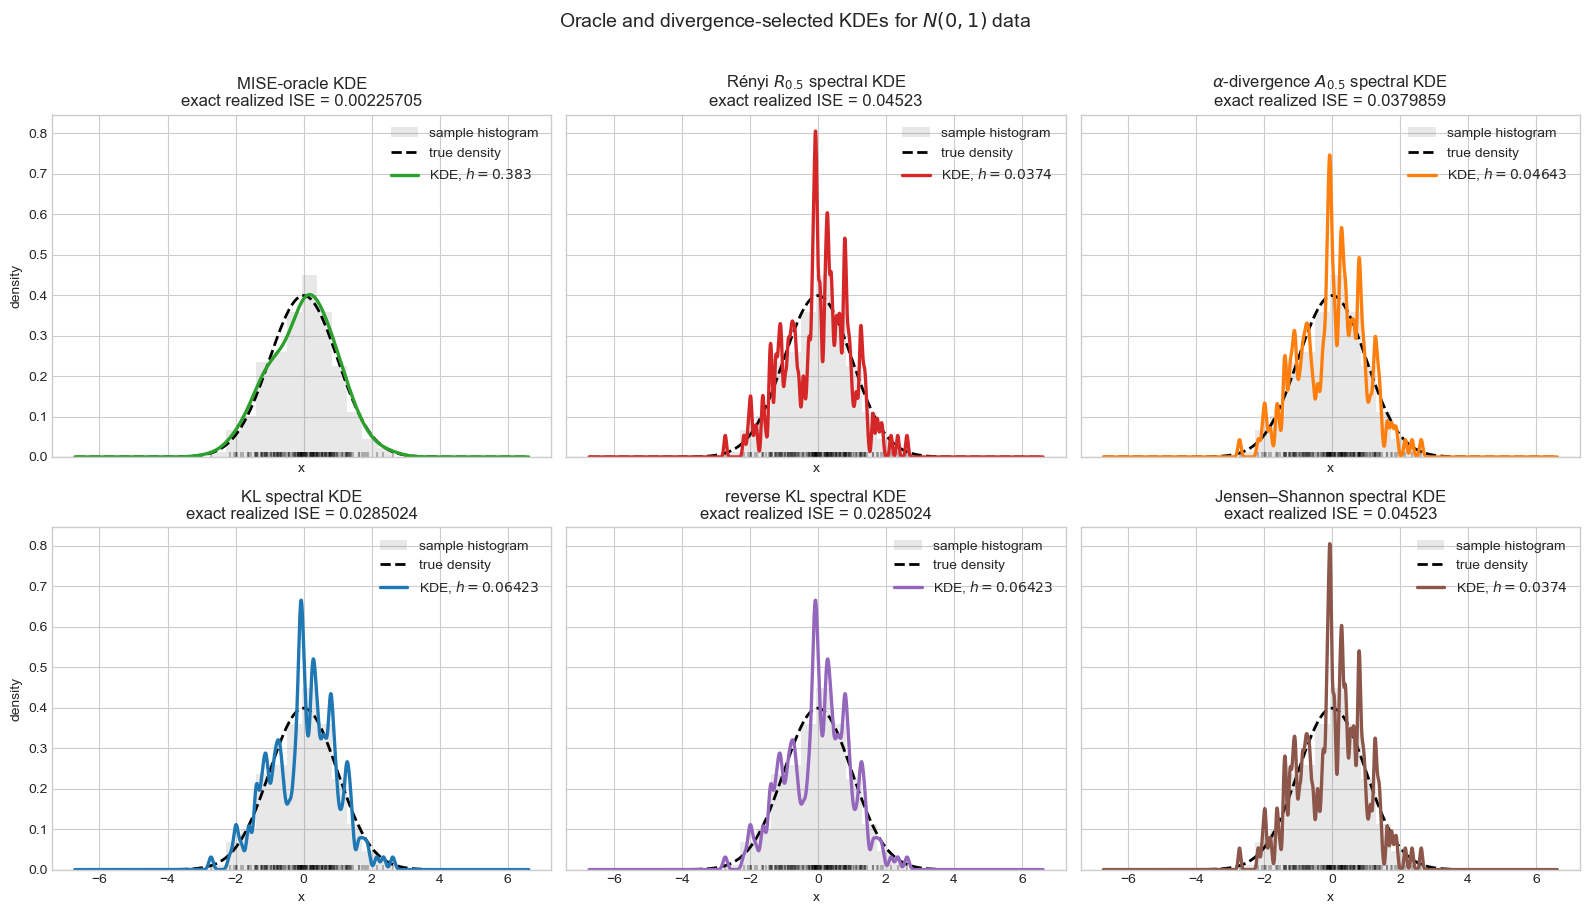

Exact realized ISE comparison
-----------------------------
MISE-oracle KDE: h = 0.38303955, ISE = 0.002257051117
Rényi $R_{0.5}$                 : h=0.037403265, ISE=0.04523003817, ratio=20.0394
$\alpha$-divergence $A_{0.5}$   : h=0.046433252, ISE=0.03798590142, ratio=16.8299
KL                              : h=0.064225647, ISE=0.02850235919, ratio=12.6281
reverse KL                      : h=0.064225647, ISE=0.02850235919, ratio=12.6281
Jensen–Shannon                  : h=0.037403265, ISE=0.04523003817, ratio=20.0394


In [12]:
all_comparison_bandwidths = [oracle_bandwidth, *spectral_selected_bandwidths.values()]
comparison_margin = max(4.0 * np.sqrt(SIGMA2), 5.0 * max(all_comparison_bandwidths))
comparison_left = min(float(X.min()) - comparison_margin, -comparison_margin)
comparison_right = max(float(X.max()) + comparison_margin, comparison_margin)
comparison_x = np.linspace(comparison_left, comparison_right, 3000)

true_density = norm.pdf(comparison_x, loc=0.0, scale=np.sqrt(SIGMA2))
oracle_density = gaussian_kde_density(comparison_x, X, oracle_bandwidth)
oracle_ise = exact_gaussian_kde_ise(X, oracle_bandwidth, SIGMA2)
spectral_density_values = {
    key: gaussian_kde_density(comparison_x, X, h)
    for key, h in spectral_selected_bandwidths.items()
}
spectral_ise_values = {
    key: exact_gaussian_kde_ise(X, h, SIGMA2)
    for key, h in spectral_selected_bandwidths.items()
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
panel_specs = [(axes.flat[0], oracle_density, oracle_bandwidth, oracle_ise, "tab:green", "MISE-oracle KDE")]
for ax, (key, label, color) in zip(axes.flat[1:], DIVERGENCE_SPECS):
    panel_specs.append((
        ax, spectral_density_values[key], spectral_selected_bandwidths[key],
        spectral_ise_values[key], color, f"{label} spectral KDE",
    ))

for ax, estimate, h_value, ise_value, color, title in panel_specs:
    ax.hist(X, bins="auto", density=True, alpha=0.18, color="gray", label="sample histogram")
    ax.plot(comparison_x, true_density, "k--", lw=2, label="true density")
    ax.plot(comparison_x, estimate, color=color, lw=2.4, label=rf"KDE, $h={h_value:.4g}$")
    ax.scatter(X, np.zeros_like(X), marker="|", s=45, color="black", alpha=0.25)
    ax.set_title(f"{title}\nexact realized ISE = {ise_value:.6g}")
    ax.set_xlabel("x")
    ax.legend()
axes[0, 0].set_ylabel("density")
axes[1, 0].set_ylabel("density")
fig.suptitle(rf"Oracle and divergence-selected KDEs for $N(0,{SIGMA2:g})$ data", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

print("Exact realized ISE comparison")
print("-----------------------------")
print(f"MISE-oracle KDE: h = {oracle_bandwidth:.8g}, ISE = {oracle_ise:.10g}")
for key, label, _ in DIVERGENCE_SPECS:
    h_value = spectral_selected_bandwidths[key]
    ise_value = spectral_ise_values[key]
    print(f"{label:32s}: h={h_value:.8g}, ISE={ise_value:.10g}, ratio={ise_value / oracle_ise:.6g}")

## 7. Stability under resampling at fixed $n$

This experiment fixes the sample size and repeatedly draws independent samples from $N(0,\sigma^2)$. On every resample, the oracle and all five divergence selectors use the **same fixed geometric bandwidth grid** from Block 2:

- the grid oracle minimizes the exact realized ISE over the grid;
- each spectral selector maximizes the stationary distribution of its divergence–Doob chain.

For speed, the repeated spectral calculations evaluate the Gaussian KDE family by binned FFT convolution before applying the same truncated composite trapezoidal quadrature. Increase `RESAMPLING_QUADRATURE_NODES` if finer quadrature is desired. Oracle selection and all reported ISEs use the exact Gaussian formulas.

In [13]:
def exact_gaussian_kde_ise_grid(
    samples: np.ndarray,
    h_grid: np.ndarray,
    sigma2: float,
) -> np.ndarray:
    """Exact realized ISE at every bandwidth in h_grid."""
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2
    kde_squared = np.empty(len(h_grid))
    for i, h in enumerate(h_grid):
        kde_squared[i] = np.exp(-squared_differences / (4.0 * h**2)).mean()
        kde_squared[i] /= 2.0 * np.sqrt(np.pi) * h
    variances = sigma2 + h_grid**2
    cross = np.exp(-samples[None, :] ** 2 / (2.0 * variances[:, None])).mean(axis=1)
    cross /= np.sqrt(2.0 * np.pi * variances)
    true_squared = 1.0 / (2.0 * np.sqrt(np.pi) * np.sqrt(sigma2))
    return np.maximum(kde_squared - 2.0 * cross + true_squared, 0.0)


def fast_gaussian_kde_family(
    samples: np.ndarray,
    h_grid: np.ndarray,
    truncation_epsilon: float,
    number_of_nodes: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Binned FFT evaluation of a Gaussian-KDE family on a truncated grid."""
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    number_of_nodes = int(number_of_nodes)
    if number_of_nodes < 101:
        raise ValueError("Use at least 101 resampling quadrature nodes.")
    if number_of_nodes % 2 == 0:
        number_of_nodes += 1

    tail_z = norm.ppf(1.0 - truncation_epsilon / 2.0)
    left = float(samples.min() - tail_z * h_grid.max())
    right = float(samples.max() + tail_z * h_grid.max())
    x_grid = np.linspace(left, right, number_of_nodes)
    dx = float(x_grid[1] - x_grid[0])
    edges = np.linspace(left - dx / 2.0, right + dx / 2.0, number_of_nodes + 1)
    counts, _ = np.histogram(samples, bins=edges)
    empirical_density = counts.astype(float) / (len(samples) * dx)
    lags = (np.arange(number_of_nodes) - number_of_nodes // 2) * dx

    density_values = np.empty((len(h_grid), number_of_nodes))
    for i, h in enumerate(h_grid):
        kernel = np.exp(-0.5 * (lags / h) ** 2) / (h * np.sqrt(2.0 * np.pi))
        density_values[i] = fftconvolve(empirical_density, kernel, mode="same") * dx

    density_values = np.maximum(density_values, 0.0)
    log_weights = composite_trapezoid_log_weights(x_grid)
    weights = np.exp(log_weights)
    masses = density_values @ weights
    density_values /= masses[:, None]
    return x_grid, density_values, log_weights


def divergence_matrices_from_density_values(
    density_values: np.ndarray,
    log_weights: np.ndarray,
    alpha: float,
    h_grid: np.ndarray,
) -> dict[str, np.ndarray]:
    """All five quadrature divergence matrices for the repeated experiments."""
    density_values = np.maximum(np.asarray(density_values, dtype=float), 1e-300)
    return assemble_all_divergence_matrices(np.log(density_values), log_weights, alpha, h_grid)


def run_one_oracle_vs_divergences_experiment(
    samples: np.ndarray,
    h_grid: np.ndarray,
    sigma2: float,
    alpha: float,
    truncation_epsilon: float,
    number_of_nodes: int,
) -> dict[str, float | int]:
    """Select exact grid-ISE oracle and all five divergence–Doob bandwidths."""
    ise_values = exact_gaussian_kde_ise_grid(samples, h_grid, sigma2)
    oracle_index = int(np.argmin(ise_values))
    _, density_values, log_weights = fast_gaussian_kde_family(
        samples, h_grid, truncation_epsilon, number_of_nodes
    )
    divergences = divergence_matrices_from_density_values(
        density_values, log_weights, alpha, h_grid
    )
    result = {
        "oracle_index": oracle_index,
        "oracle_h": float(h_grid[oracle_index]),
        "oracle_ise": float(ise_values[oracle_index]),
    }
    for key, _, _ in DIVERGENCE_SPECS:
        similarity = np.exp(-divergences[key])
        np.fill_diagonal(similarity, 1.0)
        stationary = doob_transform(similarity)["stationary_distribution"]
        selected_index = int(np.argmax(stationary))
        result[f"{key}_index"] = selected_index
        result[f"{key}_h"] = float(h_grid[selected_index])
        result[f"{key}_ise"] = float(ise_values[selected_index])
    return result

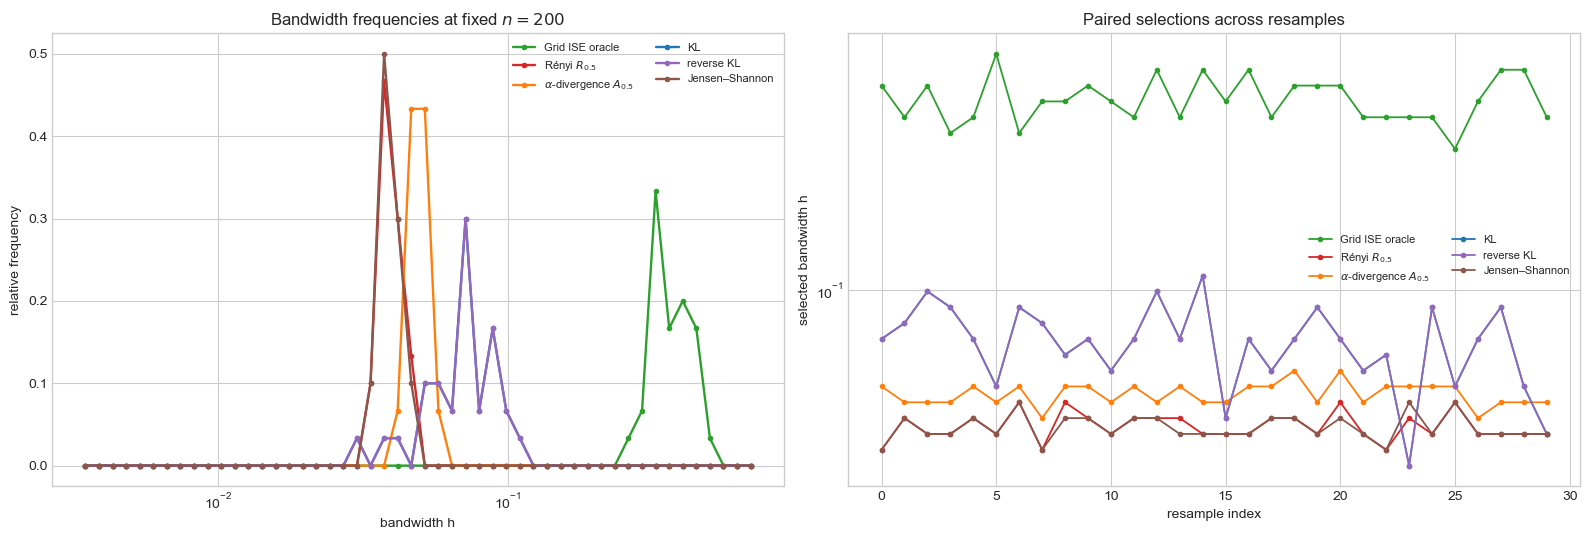

fixed sample size: 200
grid mode: scaled
number of resamples: 30
Grid ISE oracle                 : median h=0.3622974, median ISE=0.0028825749, oracle-index agreement=100.00%
Rényi $R_{0.5}$                 : median h=0.037403265, median ISE=0.034297993, oracle-index agreement=0.00%
$\alpha$-divergence $A_{0.5}$   : median h=0.049084391, median ISE=0.026899818, oracle-index agreement=0.00%
KL                              : median h=0.071559663, median ISE=0.019036749, oracle-index agreement=0.00%
reverse KL                      : median h=0.071559663, median ISE=0.019036749, oracle-index agreement=0.00%
Jensen–Shannon                  : median h=0.037403265, median ISE=0.032839419, oracle-index agreement=0.00%


In [14]:
# Fixed-n stability controls
STABILITY_N_SAMPLES = N_SAMPLES
N_STABILITY_RESAMPLES = 30
STABILITY_BASE_SEED = 700_000
RESAMPLING_QUADRATURE_NODES = 1201

stability_bandwidths = bandwidth_grid_for_sample_size(STABILITY_N_SAMPLES)
stability_results: list[dict[str, float | int]] = []
for repetition in range(N_STABILITY_RESAMPLES):
    current_rng = np.random.default_rng(STABILITY_BASE_SEED + repetition)
    current_sample = current_rng.normal(0.0, np.sqrt(SIGMA2), size=STABILITY_N_SAMPLES)
    stability_results.append(
        run_one_oracle_vs_divergences_experiment(
            current_sample, stability_bandwidths, SIGMA2, ALPHA,
            TRUNCATION_EPSILON, RESAMPLING_QUADRATURE_NODES,
        )
    )

stability_method_specs = [("oracle", "Grid ISE oracle", "tab:green"), *DIVERGENCE_SPECS]
stability_indices = {
    key: np.array([row[f"{key}_index"] for row in stability_results], dtype=int)
    for key, _, _ in stability_method_specs
}
stability_h_values = {key: stability_bandwidths[index_values] for key, index_values in stability_indices.items()}
stability_ise_values = {
    key: np.array([row[f"{key}_ise"] for row in stability_results])
    for key, _, _ in stability_method_specs
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for key, label, color in stability_method_specs:
    frequency = np.bincount(stability_indices[key], minlength=N_BANDWIDTHS) / N_STABILITY_RESAMPLES
    axes[0].plot(stability_bandwidths, frequency, marker="o", ms=3, lw=1.7, color=color, label=label)
axes[0].set_xscale("log")
axes[0].set(title=rf"Bandwidth frequencies at fixed $n={STABILITY_N_SAMPLES}$", xlabel="bandwidth h", ylabel="relative frequency")
axes[0].legend(fontsize=8, ncol=2)

repetition_indices = np.arange(N_STABILITY_RESAMPLES)
for key, label, color in stability_method_specs:
    axes[1].plot(repetition_indices, stability_h_values[key], marker="o", ms=3, lw=1.3, color=color, label=label)
axes[1].set_yscale("log")
axes[1].set(title="Paired selections across resamples", xlabel="resample index", ylabel="selected bandwidth h")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

print(f"fixed sample size: {STABILITY_N_SAMPLES}")
print(f"grid mode: {GRID_MODE}")
print(f"number of resamples: {N_STABILITY_RESAMPLES}")
for key, label, _ in stability_method_specs:
    agreement = np.mean(stability_indices[key] == stability_indices["oracle"])
    print(
        f"{label:32s}: median h={np.median(stability_h_values[key]):.8g}, "
        f"median ISE={np.median(stability_ise_values[key]):.8g}, "
        f"oracle-index agreement={agreement:.2%}"
    )

## 8. Consistency experiment with switchable grid scaling

For each $n=100,200,\ldots,1000$, this block draws 10 independent samples and repeats the oracle and all five divergence selections. The grid is rebuilt by `bandwidth_grid_for_sample_size(n)` on every sample-size step:

- `GRID_MODE = "fixed"`: $h_i\in[0.01,2]$ is unchanged with $n$;
- `GRID_MODE = "scaled"`: $h_i(n)=c_i n^{-1/5}$ with $c_i\in[0.01,2]$.

1. sample size versus selected bandwidth;
2. sample size versus exact realized ISE at the selected bandwidth.

Curves show medians across the 10 resamples and shaded regions show the interquartile ranges. In scaled mode every candidate satisfies $h_i(n)\to0$ and $nh_i(n)\to\infty$; the experiment then tests which multiplicative grid constant each divergence selector chooses.

In [15]:
CONSISTENCY_N_VALUES = np.arange(100, 1001, 100)
N_CONSISTENCY_RESAMPLES = 10
CONSISTENCY_BASE_SEED = 800_000

consistency_results = []
for n_current in CONSISTENCY_N_VALUES:
    current_bandwidths = bandwidth_grid_for_sample_size(int(n_current))
    for repetition in range(N_CONSISTENCY_RESAMPLES):
        seed = CONSISTENCY_BASE_SEED + 10_000 * int(n_current) + repetition
        current_rng = np.random.default_rng(seed)
        current_sample = current_rng.normal(0.0, np.sqrt(SIGMA2), size=int(n_current))
        result = run_one_oracle_vs_divergences_experiment(
            current_sample, current_bandwidths, SIGMA2, ALPHA,
            TRUNCATION_EPSILON, RESAMPLING_QUADRATURE_NODES,
        )
        consistency_results.append({
            "n": int(n_current), "repetition": repetition,
            "grid_min": float(current_bandwidths[0]),
            "grid_max": float(current_bandwidths[-1]),
            **result,
        })
    print(f"finished n={n_current}")


def grouped_summary(rows: list[dict], method: str, quantity: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Median, lower quartile, and upper quartile by sample size."""
    medians, lower, upper = [], [], []
    key = f"{method}_{quantity}"
    for n_current in CONSISTENCY_N_VALUES:
        values = np.array([row[key] for row in rows if row["n"] == int(n_current)], dtype=float)
        medians.append(np.median(values))
        lower.append(np.quantile(values, 0.25))
        upper.append(np.quantile(values, 0.75))
    return np.array(medians), np.array(lower), np.array(upper)

finished n=100


finished n=200


finished n=300


finished n=400


finished n=500


finished n=600


finished n=700


finished n=800


finished n=900


finished n=1000


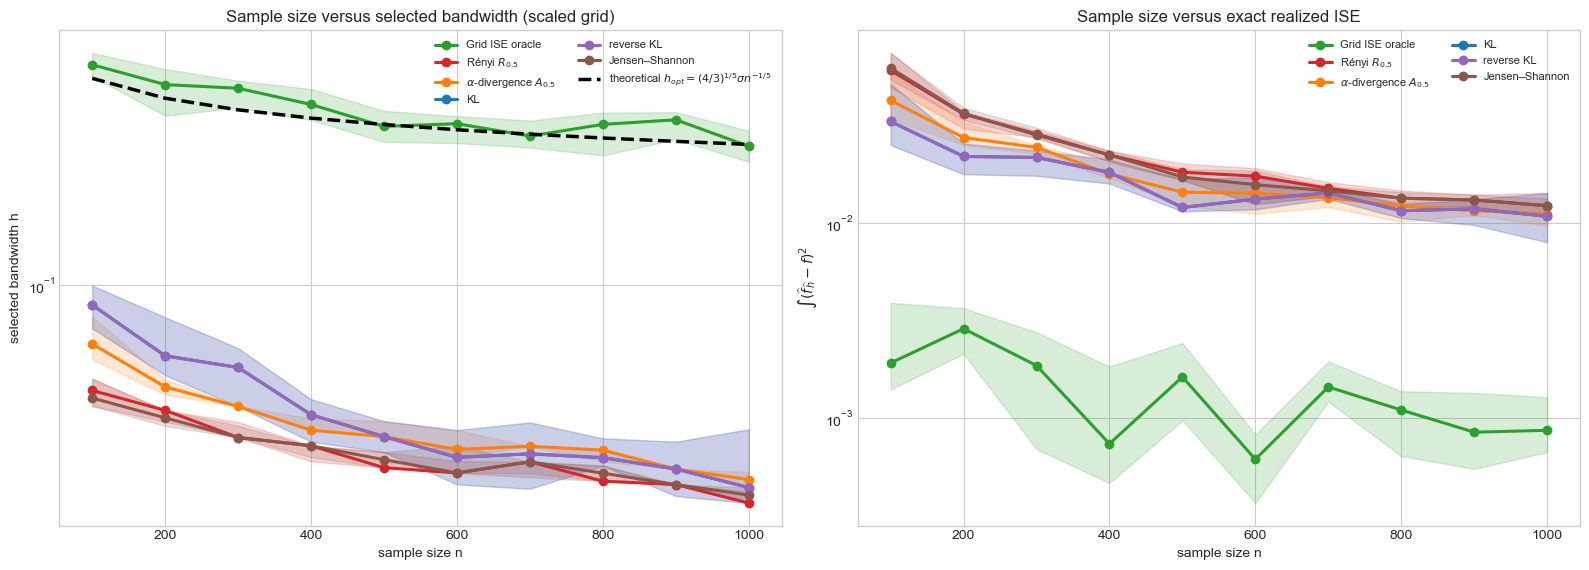

Grid mode: scaled
Median results over 10 resamples
--------------------------------

Grid ISE oracle
n       median h     median ISE
 100      0.463694    0.00192005
 200      0.403669    0.00287672
 300      0.393479    0.00186306
 400      0.351414   0.000741106
 500      0.301632    0.00162939
 600      0.307436   0.000617242
 700      0.282002      0.001448
 800      0.305924    0.00110351
 900      0.315862   0.000849668
1000      0.262586   0.000868721

Rényi $R_{0.5}$
n       median h     median ISE
 100     0.0478713     0.0603694
 200     0.0416744     0.0360651
 300     0.0344898     0.0285215
 400     0.0325614     0.0222833
 500     0.0279487     0.0181782
 600     0.0269479       0.01736
 700     0.0291136     0.0150367
 800     0.0254412     0.0133851
 900     0.0248489     0.0131115
1000     0.0218371     0.0122524

$\alpha$-divergence $A_{0.5}$
n       median h     median ISE
 100     0.0662147     0.0423657
 200     0.0490844     0.0273474
 300     0.0428165     0.0243

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
method_specs = [("oracle", "Grid ISE oracle", "tab:green"), *DIVERGENCE_SPECS]

for method, label, color in method_specs:
    median_h, q25_h, q75_h = grouped_summary(consistency_results, method, "h")
    median_ise, q25_ise, q75_ise = grouped_summary(consistency_results, method, "ise")
    axes[0].plot(CONSISTENCY_N_VALUES, median_h, marker="o", lw=2.2, color=color, label=label)
    axes[0].fill_between(CONSISTENCY_N_VALUES, q25_h, q75_h, color=color, alpha=0.18)
    axes[1].plot(CONSISTENCY_N_VALUES, median_ise, marker="o", lw=2.2, color=color, label=label)
    axes[1].fill_between(CONSISTENCY_N_VALUES, q25_ise, q75_ise, color=color, alpha=0.18)

normal_reference_constant = (4.0 / 3.0) ** (1.0 / 5.0) * np.sqrt(SIGMA2)
theoretical_optimal_bandwidth = normal_reference_constant * CONSISTENCY_N_VALUES ** (-1.0 / 5.0)
axes[0].plot(
    CONSISTENCY_N_VALUES, theoretical_optimal_bandwidth,
    "k--", lw=2.5, label=r"theoretical $h_{opt}=(4/3)^{1/5}\sigma n^{-1/5}$",
)

axes[0].set_yscale("log")
axes[0].set(title=f"Sample size versus selected bandwidth ({GRID_MODE} grid)", xlabel="sample size n", ylabel="selected bandwidth h")
axes[1].set_yscale("log")
axes[1].set(title="Sample size versus exact realized ISE", xlabel="sample size n", ylabel=r"$\int(\widehat f_{\widehat h}-f)^2$")
for ax in axes:
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

print(f"Grid mode: {GRID_MODE}")
print("Median results over 10 resamples")
print("--------------------------------")
for key, label, _ in method_specs:
    median_h, _, _ = grouped_summary(consistency_results, key, "h")
    median_ise, _, _ = grouped_summary(consistency_results, key, "ise")
    print(f"\n{label}")
    print("n       median h     median ISE")
    for n_current, h_value, ise_value in zip(CONSISTENCY_N_VALUES, median_h, median_ise):
        print(f"{n_current:4d}  {h_value:12.6g}  {ise_value:12.6g}")